# Base-model CKA — teacher vs student-base representational alignment

**Question.** Is the teacher base (`pythia-160m`) representationally closer to the student
bases it shares **initialization** with (data-seed variants) than to those it shares
**data order** with (weight-seed variants) — and does the answer differ between ordinary
text (Pile) and the number-sequence transfer data?

**Method.** Minibatch linear CKA with the unbiased HSIC₁ estimator
(`scripts.compute_cka` → `pipelines/cka_pipeline.py`), position-sampled rows
(never position 0; numbers condition: digit completion tokens only), all layer pairs
(slot 0 = embeddings, slots 1–12 = raw post-block residuals).

**Reading rules**

- The readout is the **contrast** between pair groups — `primary_data` (ref, dᵢ) vs
  `primary_weight` (ref, wᵢ) — and between data conditions. Absolute CKA values are
  uninterpretable except against the **ceiling** (ref vs itself ⇒ 1.0) and **floor**
  (row-permuted ⇒ ≈ 0) controls. Within-arm pairs are the reference distribution for
  how much CKA varies among "equivalent" models.
- Heatmap orientation is fixed: model A (ref/teacher) layers on **rows**, model B on
  **columns**, input→output from bottom-left; color scale pinned to [0, 1] everywhere.
- Raw residual-stream CKA can saturate under a few dominant directions — a uniformly
  bright matrix means saturation, not similarity; lean on the PC-ablated variants
  (`pc1/pc3/pc5` = top-r PCs projected out per model×layer). A bright ridge *off* the
  diagonal means depth-shifted correspondence (the diagonal then understates similarity).
- Early layers are typically more similar across seeds than later layers — a diagonal
  curve declining with depth is expected, not a bug.
- A flat contrast does **not** falsify representation-mediated transfer: linear CKA
  weights directions by variance and may be blind to a low-variance trait-relevant
  subspace.

**Adding runs.** `uv run python -m scripts.compute_cka --condition pile|numbers ...
--run-tag <tag>` writes to `{output_root}/cka/base/<tag>/` (base-vs-base runs; per-student runs live in the student run dir); re-run this notebook —
it discovers whatever run tags are on disk (scratch tags listed in `EXCLUDE` are hidden).

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from subliminal_learning.analysis.setup import bootstrap, set_plot_style
from subliminal_learning.analysis import frames, plots

ROOT, OUTPUT_ROOT = bootstrap()
set_plot_style()
CKA_ROOT = OUTPUT_ROOT / "cka" / "base"

GROUP_ORDER = ["primary", "primary_data", "primary_weight", "within_data",
               "within_weight", "ceiling", "self", "floor"]
GROUP_COLORS = {
    "primary": "#2ca02c",         # explicit --model-a/--model-b pair (finetuned mode)
    "primary_data": "#d62728",    # ref vs data-seed (shared init)  — the hypothesis arm
    "primary_weight": "#1f77b4",  # ref vs weight-seed (shared data order)
    "within_data": "#ff9896",
    "within_weight": "#aec7e8",
    "ceiling": "black",
    "self": "#7f7f7f",
    "floor": "#c7c7c7",
}
VARIANT_ORDER = ["raw", "pc1", "pc3", "pc5", "meanpool"]


def load_mat(run_tag, pair, variant):
    return np.load(CKA_ROOT / run_tag / f"cka__{pair}__{variant}.npy")

## 1 · Runs on disk

Run tags are DERIVED, never hand-chosen: `pile`, or `numbers_{generator}_{mode}` read
off the pool path, plus a deterministic `_axis{value}` suffix for any axis deviating
from the canonical defaults (`scripts/compute_cka._CANONICAL`). Canonical runs
(1 position per sequence — every batch row from a different sequence):

- **`pile`** — single-pass auto-sized pool (k × seqs_per_batch = 25,600 docs of
  held-out Pile; no doc revisited).
- **`numbers_base160m_prefix`** — numbers generated by the **teacher base model**
  (untuned `pythia-160m`), `prefix` filter mode; the students' EXACT training set
  (fixed 10k @ seed-42 subsample, the distillation convention). 512 of the 10k rows
  are reserved for PC estimation; the CKA accumulation sees the other 9,488.

Each run's `meta.json` / `cka_manifest.json` records the pool path, file sha256,
tokenized-pool sha256, subsample settings, and skip counts, so provenance is pinned
in artifacts, not tag names.

In [2]:
EXCLUDE = set()  # scratch run tags to hide from the analysis

# A run is loaded ONLY if its cka_manifest.json exists — the manifest is written
# last by the pipeline, so its presence certifies a complete run produced under
# exactly the recorded identity. Partial/interrupted dirs are skipped loudly.
runs = {}
for run_dir in sorted(p for p in CKA_ROOT.iterdir() if p.is_dir()):
    if run_dir.name in EXCLUDE:
        continue
    if not (run_dir / "cka_manifest.json").exists():
        print(f"SKIPPING {run_dir.name}: no cka_manifest.json (incomplete/interrupted run)")
        continue
    runs[run_dir.name] = frames.read_json(run_dir / "summary.json")
assert runs, f"no complete CKA runs under {CKA_ROOT}; run scripts.compute_cka first"

for tag, s in runs.items():
    c = s["meta"]["config"]
    print(f"{tag:32s} condition={c['condition']:8s} k={c['k_batches']:>4} "
          f"m={c['batch_rows']} pos/seq={c['positions_per_seq']} "
          f"models={len(s['meta']['models'])} pool={s['meta']['pool_n_seqs']} seqs")
    print(f"{'':32s} source: {s['meta']['pool_source']}")


numbers_base160m_prefix          condition=numbers  k= 100 m=256 pos/seq=1 models=7 pool=10000 seqs
                                 source: /mnt/ssd-2/soar-subliminal/angela/outputs/numbers/controls/base/pythia-160m/ex10-20/modes/prefix/filtered.jsonl
pile                             condition=pile     k= 100 m=256 pos/seq=1 models=7 pool=26112 seqs
                                 source: monology/pile-uncopyrighted:validation


In [3]:
df = pd.DataFrame(
    {"run": tag, "condition": s["meta"]["config"]["condition"], **row}
    for tag, s in runs.items()
    for row in s["rows"]
)
df["group"] = pd.Categorical(df["group"], GROUP_ORDER, ordered=True)
variants = [v for v in VARIANT_ORDER if v in set(df["variant"])]
df["variant"] = pd.Categorical(df["variant"], variants, ordered=True)
RUNS = list(runs)
print(f"{len(df)} pair x variant rows across {len(RUNS)} run(s); variants: {variants}")


200 pair x variant rows across 2 run(s); variants: ['raw', 'pc1', 'pc3', 'pc5', 'meanpool']


## 2 · Summary tables

Per-pair diagonal means first (each cell = mean over the 13 diagonal CKA entries of that
single pair), then the across-pair aggregate per group (mean, min–max over pairs). No
cross-condition averaging anywhere — conditions are separate tables.

In [4]:
for tag in RUNS:
    d = df[df.run == tag]
    tab = (d.pivot_table(index=["group", "pair"], columns="variant",
                         values="diag_mean", observed=True)
             .reindex(columns=variants).round(3))
    print(f"=== {tag} — per-pair mean diagonal CKA ===")
    display(tab)


=== numbers_base160m_prefix — per-pair mean diagonal CKA ===


variant                                         raw    pc1    pc3    pc5  \
group          pair                                                        
primary_data   full-seed0__data-seed1         0.826  0.712  0.681  0.694   
               full-seed0__data-seed2         0.808  0.760  0.631  0.688   
               full-seed0__data-seed3         0.808  0.729  0.640  0.694   
primary_weight full-seed0__weight-seed1       0.867  0.772  0.653  0.699   
               full-seed0__weight-seed2       0.842  0.742  0.716  0.696   
               full-seed0__weight-seed3       0.845  0.718  0.661  0.695   
within_data    data-seed1__data-seed2         0.859  0.765  0.691  0.717   
               data-seed1__data-seed3         0.830  0.735  0.673  0.698   
               data-seed2__data-seed3         0.828  0.786  0.681  0.708   
within_weight  weight-seed1__weight-seed2     0.864  0.736  0.675  0.696   
               weight-seed1__weight-seed3     0.857  0.715  0.682  0.709   
               weight-seed2__weight-seed3     0.884  0.768  0.706  0.723   
ceiling        self__full-seed0               1.000  1.000  1.000  1.000   
self           self__data-seed1               1.000  1.000  1.000  1.000   
               self__data-seed2               1.000  1.000  1.000  1.000   
               self__data-seed3               1.000  1.000  1.000  1.000   
               self__weight-seed1             1.000  1.000  1.000  1.000   
               self__weight-seed2             1.000  1.000  1.000  1.000   
               self__weight-seed3             1.000  1.000  1.000  1.000   
floor          floor__full-seed0__data-seed1  0.000  0.000  0.000  0.000   

variant                                       meanpool  
group          pair                                     
primary_data   full-seed0__data-seed1            0.838  
               full-seed0__data-seed2            0.818  
               full-seed0__data-seed3            0.820  
primary_weight full-seed0__weight-seed1          0.861  
               full-seed0__weight-seed2          0.852  
               full-seed0__weight-seed3          0.862  
within_data    data-seed1__data-seed2            0.878  
               data-seed1__data-seed3            0.839  
               data-seed2__data-seed3            0.841  
within_weight  weight-seed1__weight-seed2        0.876  
               weight-seed1__weight-seed3        0.862  
               weight-seed2__weight-seed3        0.879  
ceiling        self__full-seed0                  1.000  
self           self__data-seed1                  1.000  
               self__data-seed2                  1.000  
               self__data-seed3                  1.000  
               self__weight-seed1                1.000  
               self__weight-seed2                1.000  
               self__weight-seed3                1.000  
floor          floor__full-seed0__data-seed1     0.001

=== pile — per-pair mean diagonal CKA ===


variant                                         raw    pc1    pc3    pc5  \
group          pair                                                        
primary_data   full-seed0__data-seed1         0.900  0.589  0.648  0.675   
               full-seed0__data-seed2         0.924  0.581  0.635  0.687   
               full-seed0__data-seed3         0.820  0.597  0.627  0.668   
primary_weight full-seed0__weight-seed1       0.935  0.611  0.670  0.680   
               full-seed0__weight-seed2       0.759  0.617  0.645  0.682   
               full-seed0__weight-seed3       0.929  0.608  0.616  0.660   
within_data    data-seed1__data-seed2         0.930  0.667  0.650  0.697   
               data-seed1__data-seed3         0.789  0.610  0.651  0.687   
               data-seed2__data-seed3         0.807  0.606  0.630  0.680   
within_weight  weight-seed1__weight-seed2     0.752  0.568  0.630  0.667   
               weight-seed1__weight-seed3     0.929  0.608  0.629  0.663   
               weight-seed2__weight-seed3     0.775  0.666  0.657  0.686   
ceiling        self__full-seed0               1.000  1.000  1.000  1.000   
self           self__data-seed1               1.000  1.000  1.000  1.000   
               self__data-seed2               1.000  1.000  1.000  1.000   
               self__data-seed3               1.000  1.000  1.000  1.000   
               self__weight-seed1             1.000  1.000  1.000  1.000   
               self__weight-seed2             1.000  1.000  1.000  1.000   
               self__weight-seed3             1.000  1.000  1.000  1.000   
floor          floor__full-seed0__data-seed1 -0.000 -0.000 -0.001 -0.001   

variant                                       meanpool  
group          pair                                     
primary_data   full-seed0__data-seed1            0.909  
               full-seed0__data-seed2            0.920  
               full-seed0__data-seed3            0.879  
primary_weight full-seed0__weight-seed1          0.928  
               full-seed0__weight-seed2          0.883  
               full-seed0__weight-seed3          0.911  
within_data    data-seed1__data-seed2            0.946  
               data-seed1__data-seed3            0.903  
               data-seed2__data-seed3            0.902  
within_weight  weight-seed1__weight-seed2        0.884  
               weight-seed1__weight-seed3        0.924  
               weight-seed2__weight-seed3        0.918  
ceiling        self__full-seed0                  1.000  
self           self__data-seed1                  1.000  
               self__data-seed2                  1.000  
               self__data-seed3                  1.000  
               self__weight-seed1                1.000  
               self__weight-seed2                1.000  
               self__weight-seed3                1.000  
floor          floor__full-seed0__data-seed1     0.000

In [5]:
agg = (df.groupby(["run", "variant", "group"], observed=True)["diag_mean"]
         .agg(["mean", "min", "max", "count"]).round(3))
print("Across-pair aggregate per group (mean/min/max over pairs in the group):")
display(agg)


Across-pair aggregate per group (mean/min/max over pairs in the group):


mean    min    max  count
run                     variant  group                                     
numbers_base160m_prefix raw      primary_data    0.814  0.808  0.826      3
                                 primary_weight  0.851  0.842  0.867      3
                                 within_data     0.839  0.828  0.859      3
                                 within_weight   0.868  0.857  0.884      3
                                 ceiling         1.000  1.000  1.000      1
...                                                ...    ...    ...    ...
pile                    meanpool within_data     0.917  0.902  0.946      3
                                 within_weight   0.909  0.884  0.924      3
                                 ceiling         1.000  1.000  1.000      1
                                 self            1.000  1.000  1.000      6
                                 floor           0.000  0.000  0.000      1

[70 rows x 4 columns]

## 3 · Headline contrast — (ref, dᵢ) vs (ref, wᵢ), bracketed by controls

One panel per run. Each dot is one pair's mean diagonal CKA; group means connected
across variants. The question is whether red (shared init) sits above blue (shared
data order), and whether PC ablation opens up a contrast that raw CKA saturates away.

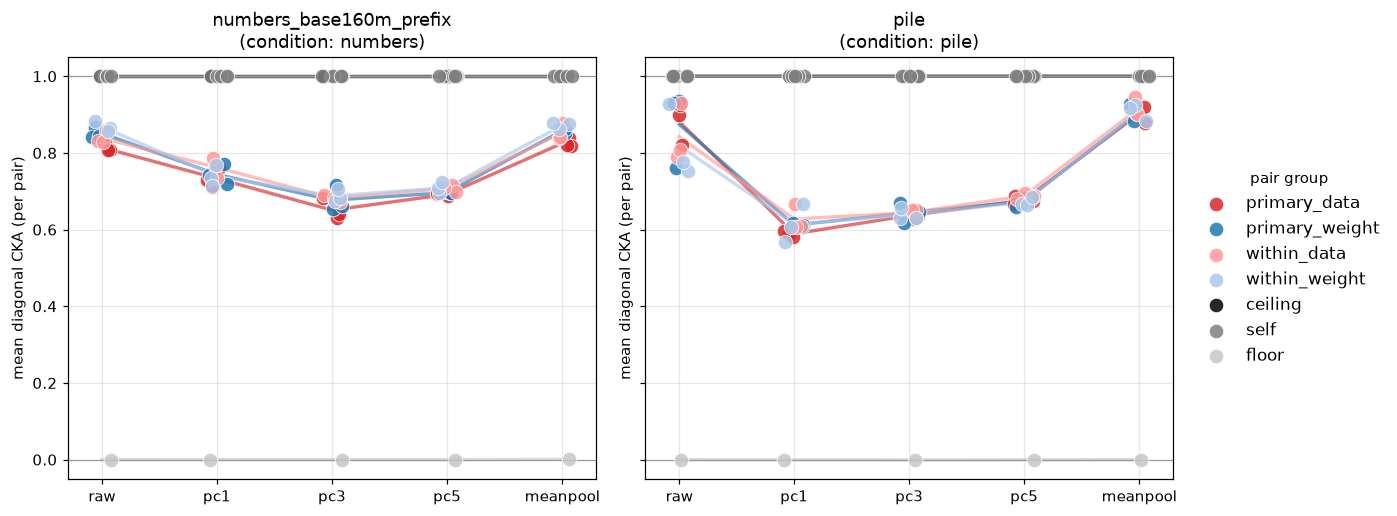

In [6]:
fig, axes = plt.subplots(1, len(RUNS), figsize=(6.4 * len(RUNS), 4.8),
                         sharey=True, squeeze=False)
x_pos = {v: i for i, v in enumerate(variants)}
rng = np.random.default_rng(0)
for ax, tag in zip(axes[0], RUNS):
    d = df[df.run == tag]
    for grp, dg in d.groupby("group", observed=True):
        xs = dg["variant"].map(x_pos).astype(float) + rng.uniform(-0.09, 0.09, len(dg))
        ax.scatter(xs, dg["diag_mean"], s=90, alpha=0.85, zorder=3,
                   color=GROUP_COLORS[grp], edgecolor="white", linewidth=0.6, label=grp)
        gm = dg.groupby("variant", observed=True)["diag_mean"].mean()
        ax.plot([x_pos[v] for v in gm.index], gm.values, color=GROUP_COLORS[grp],
                linewidth=2.2, alpha=0.65, zorder=2)
    ax.axhline(0, color="0.6", linewidth=0.8)
    ax.axhline(1, color="0.6", linewidth=0.8)
    ax.set_xticks(range(len(variants)), variants)
    ax.set_title(f"{tag}\n(condition: {d['condition'].iloc[0]})")
    ax.set_ylabel("mean diagonal CKA (per pair)")
plots.right_legend(axes[0, -1], fontsize=11, title="pair group")
fig.tight_layout()
plt.show()


## 4 · Alignment vs depth — per-layer diagonal curves

Diagonal entry (i, i) per layer slot, per pair. Left: raw; right: pc3-ablated.
The floor curve shows the noise level per layer; ceiling pins 1.0.

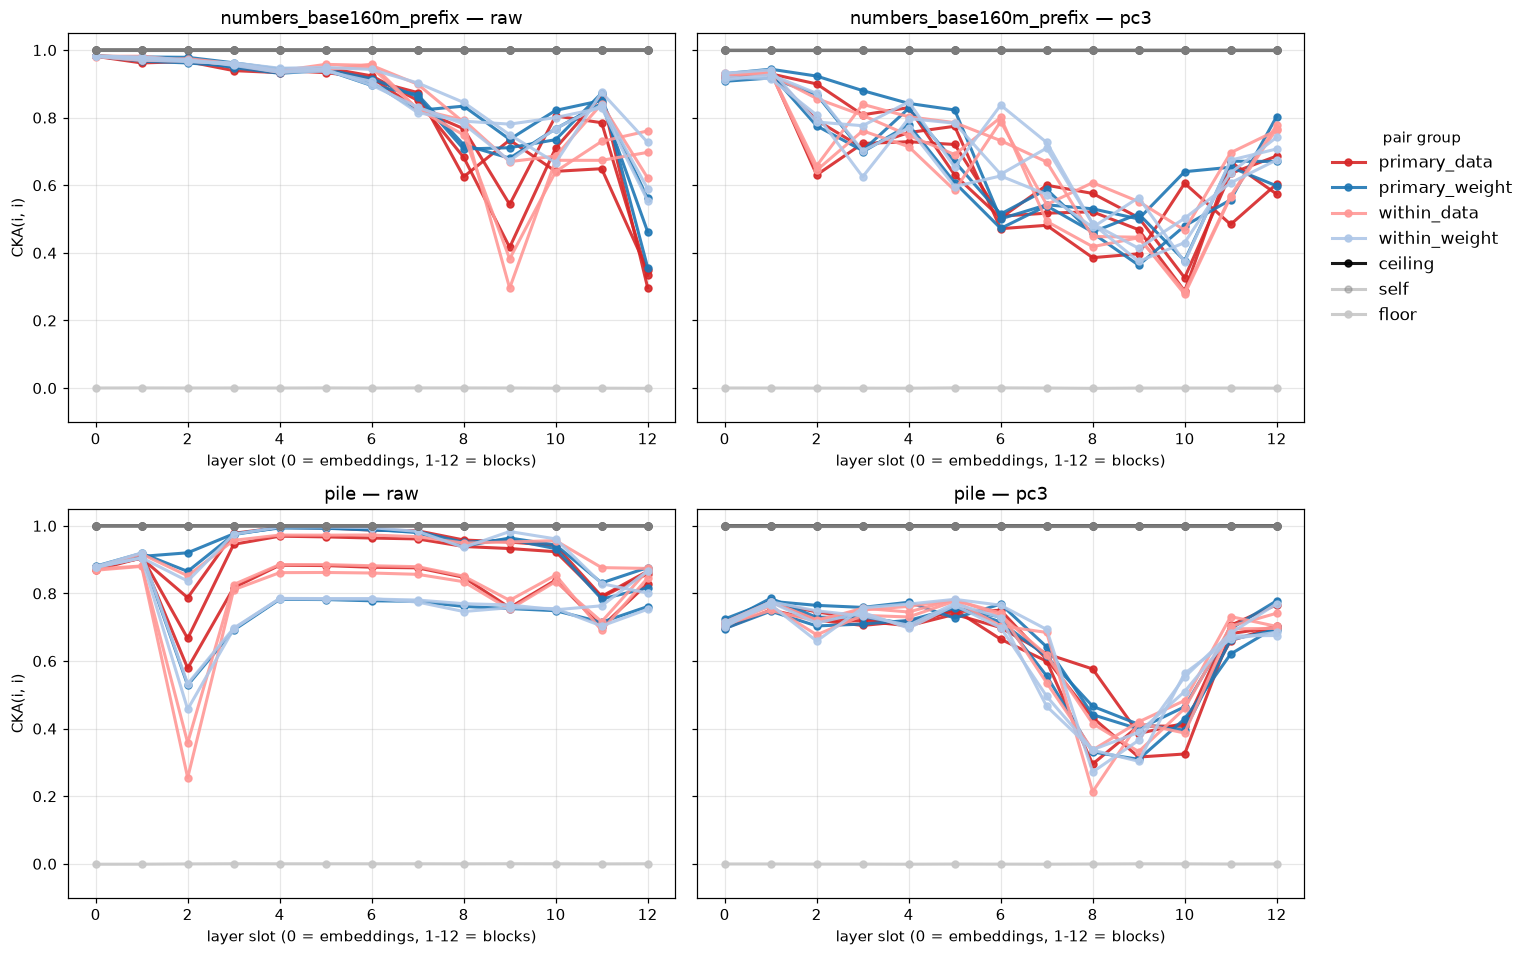

In [7]:
show_variants = [v for v in ["raw", "pc3"] if v in variants] or variants[:1]
fig, axes = plt.subplots(len(RUNS), len(show_variants),
                         figsize=(7.0 * len(show_variants), 4.4 * len(RUNS)),
                         sharey=True, squeeze=False)
for r, tag in enumerate(RUNS):
    d = df[df.run == tag]
    for c, variant in enumerate(show_variants):
        ax = axes[r, c]
        for _, row in d[d.variant == variant].iterrows():
            diag = np.diag(load_mat(tag, row["pair"], variant))
            grp = row["group"]
            ax.plot(range(len(diag)), diag, color=GROUP_COLORS[grp], linewidth=2.0,
                    alpha=0.4 if grp in ("self",) else 0.9,
                    marker="o", markersize=4.5, label=grp)
        ax.set_title(f"{tag} — {variant}")
        ax.set_xlabel("layer slot (0 = embeddings, 1-12 = blocks)")
        if c == 0:
            ax.set_ylabel("CKA(i, i)")
        ax.set_ylim(-0.1, 1.05)
handles, labels = axes[0, 0].get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plots.right_legend(axes[0, -1], handles=list(by_label.values()),
                   labels=list(by_label.keys()), fontsize=11, title="pair group")
fig.tight_layout()
plt.show()


## 5 · Cross-layer heatmaps — primary pairs

Full 13×13 CKA matrices, ref layers on rows, variant-model layers on columns,
input→output from bottom-left, scale pinned to [0, 1]. Top row: data-seeds
(shared init); bottom row: weight-seeds (shared data order). A bright ridge on the
diagonal = depth-matched correspondence; uniform brightness = saturation (see the
PC-ablated grid below).

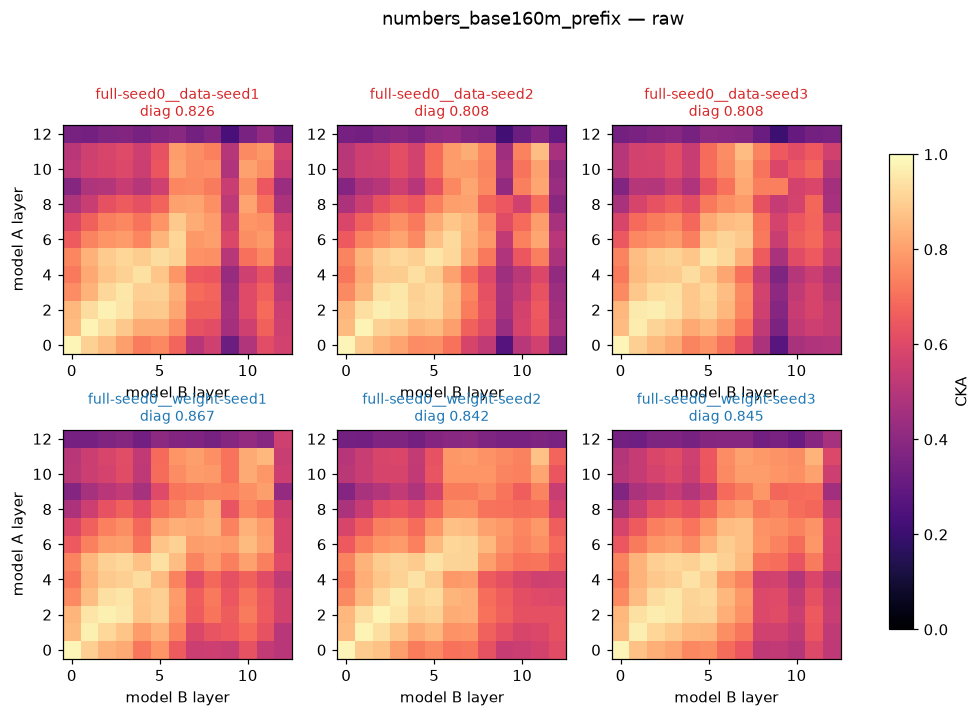

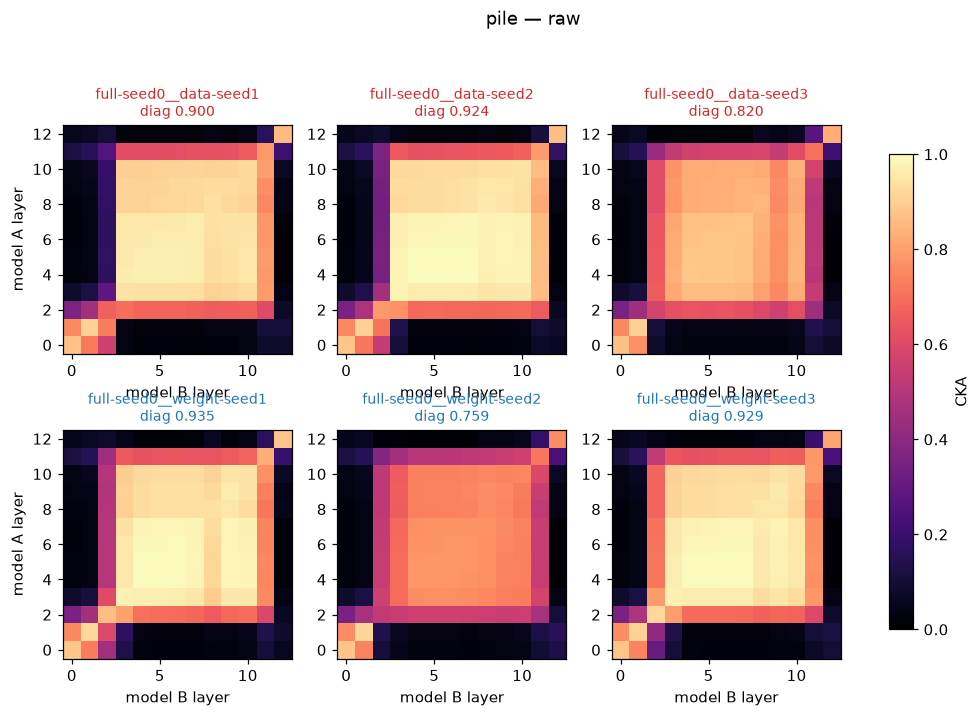

In [8]:
def primary_grid(tag, variant):
    d = df[(df.run == tag) & (df.variant == variant)]
    rows = [(g, d[d.group == g]["pair"].tolist())
            for g in ("primary", "primary_data", "primary_weight")]
    rows = [(g, ps) for g, ps in rows if ps]
    if not rows:
        print(f"{tag}: no primary-group pairs — skipping grid")
        return
    ncols = max(len(ps) for _, ps in rows)
    fig, axes = plt.subplots(len(rows), ncols,
                             figsize=(3.4 * ncols + 1.2, 3.3 * len(rows)),
                             squeeze=False)
    for r, (grp, pairs_) in enumerate(rows):
        for c in range(ncols):
            ax = axes[r, c]
            if c >= len(pairs_):
                ax.axis("off")
                continue
            mat = load_mat(tag, pairs_[c], variant)
            im = ax.imshow(mat, vmin=0, vmax=1, origin="lower", cmap="magma")
            ax.set_title(f"{pairs_[c]}\ndiag {np.nanmean(np.diag(mat)):.3f}",
                         fontsize=9, color=GROUP_COLORS[grp])
            ax.grid(False)
            if c == 0:
                ax.set_ylabel("model A layer")
            ax.set_xlabel("model B layer")
    fig.colorbar(im, ax=axes, shrink=0.85, label="CKA")
    fig.suptitle(f"{tag} — {variant}", y=1.02)
    plt.show()


for tag in RUNS:
    primary_grid(tag, "raw")

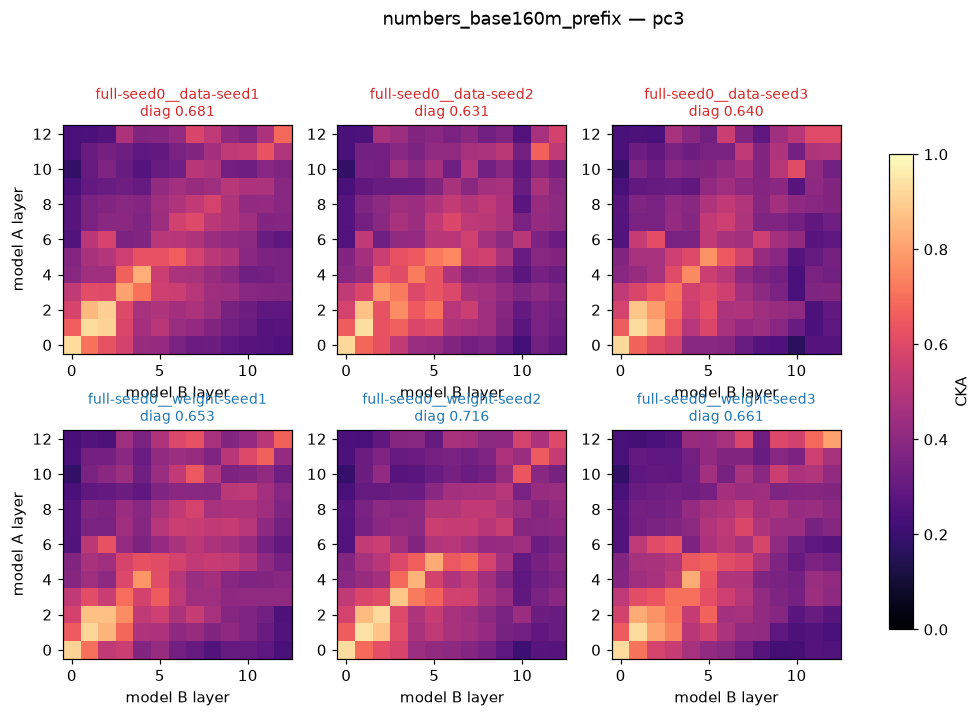

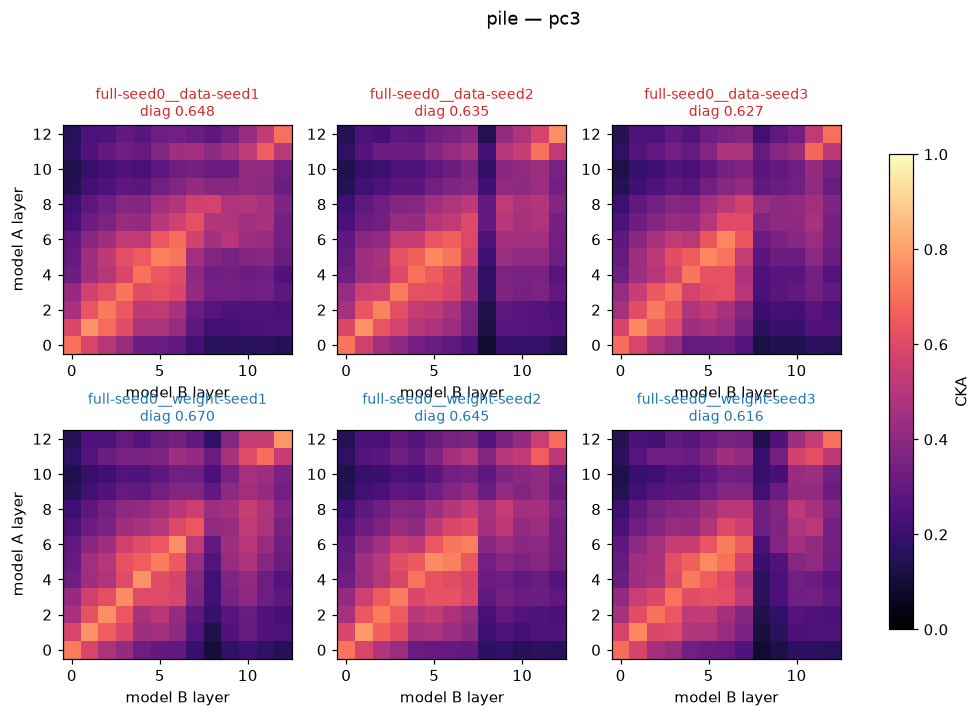

In [9]:
for tag in RUNS:
    if "pc3" in variants:
        primary_grid(tag, "pc3")


## 6 · The contrast heatmap — mean(ref, dᵢ) − mean(ref, wᵢ)

The layer-pair-resolved version of the headline: positive (red) = data-seed pairs more
aligned with the ref than weight-seed pairs at that layer pair. Diverging scale centered
on 0 (fixed ±0.1; values beyond saturate).

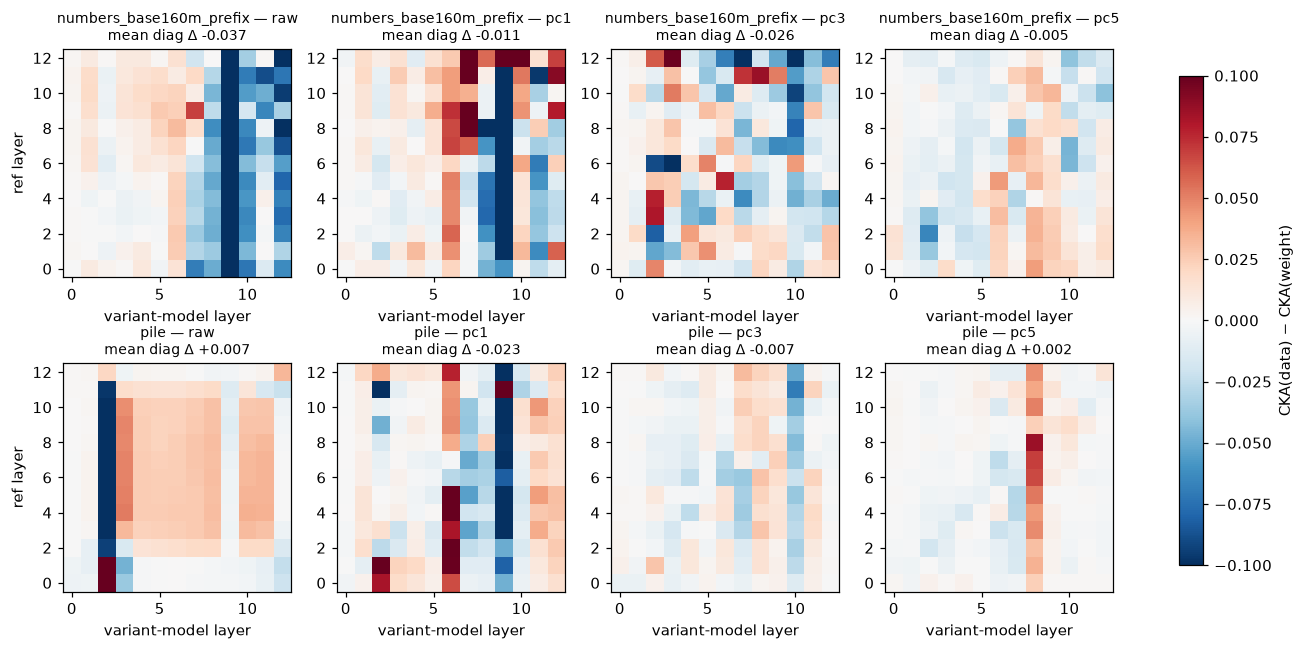

In [10]:
show_all = [v for v in variants if v != "meanpool"]
# Only PolyPythia-matrix runs have both contrast arms; explicit --model-a/--model-b
# runs (single "primary" pair) have no d-vs-w contrast and are skipped here.
contrast_runs = [
    tag for tag in RUNS
    if not df[(df.run == tag) & (df.group == "primary_data")].empty
    and not df[(df.run == tag) & (df.group == "primary_weight")].empty
]
skipped = [t for t in RUNS if t not in contrast_runs]
if skipped:
    print(f"no d-vs-w arms (explicit-pair runs) — skipping: {skipped}")
if contrast_runs:
    fig, axes = plt.subplots(len(contrast_runs), len(show_all),
                             figsize=(3.6 * len(show_all) + 1.0, 3.4 * len(contrast_runs)),
                             squeeze=False)
    for r, tag in enumerate(contrast_runs):
        d = df[df.run == tag]
        for c, variant in enumerate(show_all):
            ax = axes[r, c]
            # nanmean: pc-ablated matrices can carry NaN cells (near-degenerate
            # self-HSIC; the pipeline warns and lists them in the manifest).
            md_ = np.nanmean([load_mat(tag, p, variant)
                              for p in d[(d.group == "primary_data") & (d.variant == variant)]["pair"]], axis=0)
            mw = np.nanmean([load_mat(tag, p, variant)
                             for p in d[(d.group == "primary_weight") & (d.variant == variant)]["pair"]], axis=0)
            diff = md_ - mw
            im = ax.imshow(diff, vmin=-0.1, vmax=0.1, origin="lower", cmap="RdBu_r")
            ax.set_title(f"{tag} — {variant}\nmean diag Δ {np.nanmean(np.diag(diff)):+.3f}",
                         fontsize=9)
            ax.grid(False)
            if c == 0:
                ax.set_ylabel("ref layer")
            ax.set_xlabel("variant-model layer")
    fig.colorbar(im, ax=axes, shrink=0.85, label="CKA(data) − CKA(weight)")
    plt.show()

## 7 · Within-model self-heatmaps (block-structure diagnostic)

Each model vs itself. A large saturated off-diagonal block means that depth range of the
cross-model heatmaps is uninformative in raw form — lean on the PC-ablated variants
there.

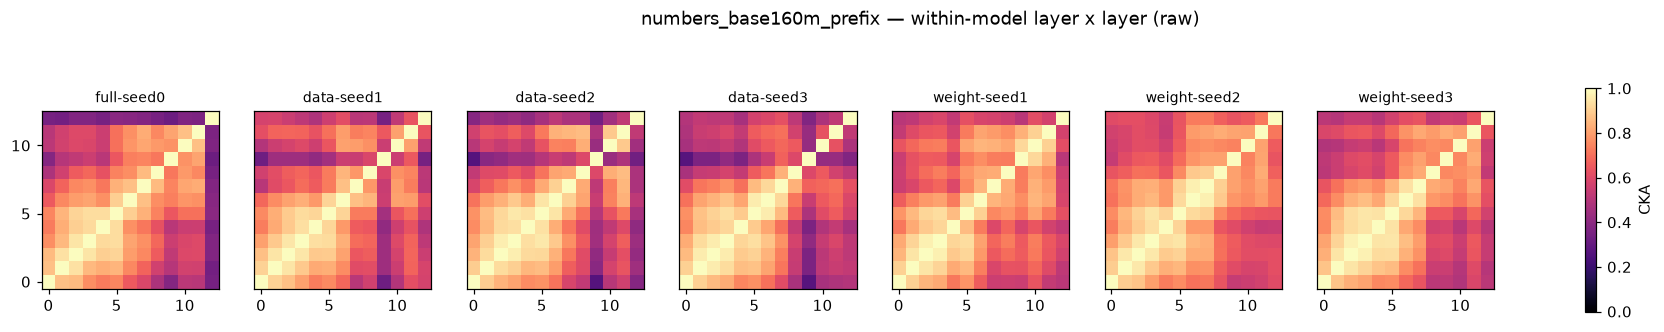

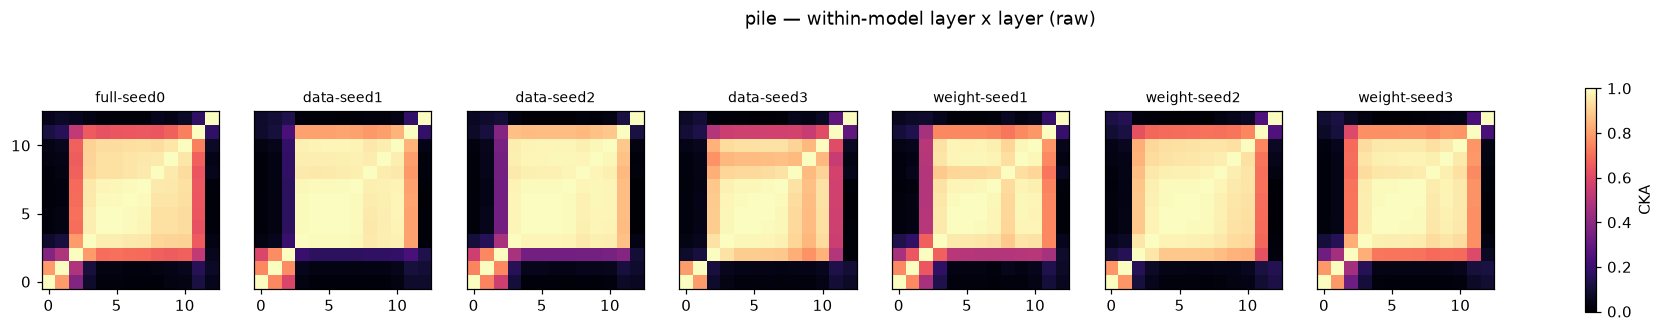

In [11]:
for tag in RUNS:
    d = df[(df.run == tag) & (df.variant == "raw") & (df.group.isin(["ceiling", "self"]))]
    pairs_ = d["pair"].tolist()
    fig, axes = plt.subplots(1, len(pairs_), figsize=(2.9 * len(pairs_) + 1.0, 3.1),
                             squeeze=False)
    for c, pair in enumerate(pairs_):
        ax = axes[0, c]
        im = ax.imshow(load_mat(tag, pair, "raw"), vmin=0, vmax=1, origin="lower",
                       cmap="magma")
        ax.set_title(pair.removeprefix("self__"), fontsize=9)
        ax.grid(False)
        if c:
            ax.set_yticks([])
    fig.colorbar(im, ax=axes, shrink=0.85, label="CKA")
    fig.suptitle(f"{tag} — within-model layer x layer (raw)", y=1.05)
    plt.show()


## 8 · Convergence — running mean diagonal CKA vs k

Sanity check on the minibatch estimate: curves must be visually flat by the final k.
If a curve is still drifting, extend the run (`--k-batches 200`).

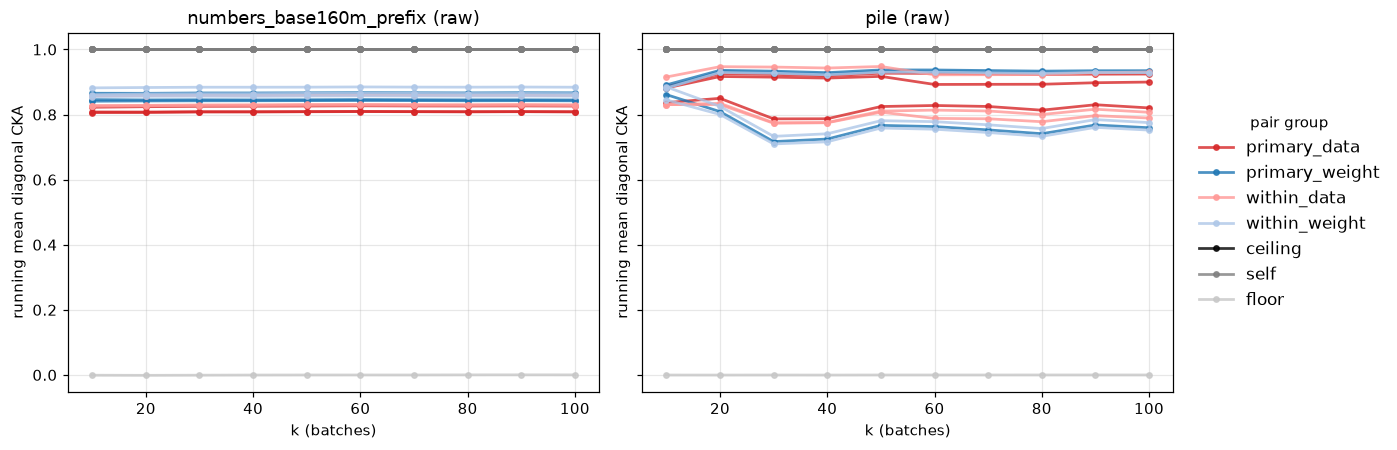

In [12]:
fig, axes = plt.subplots(1, len(RUNS), figsize=(6.4 * len(RUNS), 4.2),
                         sharey=True, squeeze=False)
for ax, tag in zip(axes[0], RUNS):
    curves = runs[tag]["convergence_curves"]
    for _, row in df[(df.run == tag) & (df.variant == "raw")].iterrows():
        curve = curves[f"{row['pair']}__raw"]
        ax.plot([p["k"] for p in curve], [p["diag_mean"] for p in curve],
                color=GROUP_COLORS[row["group"]], linewidth=1.8, alpha=0.8,
                marker="o", markersize=3.5, label=row["group"])
    ax.set_title(f"{tag} (raw)")
    ax.set_xlabel("k (batches)")
    ax.set_ylabel("running mean diagonal CKA")
handles, labels = axes[0, -1].get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plots.right_legend(axes[0, -1], handles=list(by_label.values()),
                   labels=list(by_label.keys()), fontsize=11, title="pair group")
fig.tight_layout()
plt.show()


## 9 · Methods notes for the writeup

Deliberate deviations from common LLM CKA practice (state these rather than leave
implicit):

1. Most LLM work computes full-batch linear CKA with the **biased** HSIC₀ estimator over
   pooled token positions. We use the Nguyen et al. **minibatch unbiased** estimator with
   independent position sampling (1–4 positions/sequence, never position 0, digit-only
   completion tokens in the numbers condition), which is stricter about the U-statistic's
   independence assumption. The `meanpool` variant (one mean-pooled row per sequence) is
   the faithfulness check against the source paper's one-row-per-example setup — report
   it alongside, don't substitute it for the position-sampled primary.
2. No claim rests on absolute CKA values — only on contrasts bracketed by the
   floor/ceiling controls.
3. A near-identical CKA across arms does NOT falsify representation-mediated transfer
   (variance-weighting blindness to low-variance trait subspaces). A cheap robustness
   add if the contrast carries weight: a complementary geometry metric (e.g. mutual-kNN
   overlap) on the same activation samples.

## 10 · Deck figure — CKA contrast + CKA/Procrustes on the number channel (headline_deck slide 10)

Slide-10 figure of `docs/results/headline_deck.pptx`, rebuilt from this notebook's frames
plus the Procrustes arrays in the *pairs* output tree.

**Construction.**

- **Row unit** everywhere = one base-model pair (one CKA/Procrustes run over the same
  forward passes); dots are individual pairs, bars are the group mean over pairs.
- **Panel 1** (contrast, all variants): from `df` — per variant, mean `diag_mean` over the
  3 `primary_data` pairs minus the mean over the 3 `primary_weight` pairs, for the two runs
  in `RUNS` (`numbers_base160m_prefix` = numbers channel, `pile`). Negative = weight-seeds
  are *more* similar to the reference base.
- **Panels 2–3**: numbers channel, `raw` variant only. Groups: **orig↔ds** = the 3
  `primary_data` pairs (full-seed0 vs data-seed1/2/3), **orig↔ws** = the 3 `primary_weight`
  pairs, **ds1↔ws1** = the single cross-arm pair, which lives in its own pair run
  (`cka/pairs/numbers_base160m_prefix_ds1_ws1`) and not in the base matrix run.
- **Layer aggregation** is the same convention as "mean diagonal CKA" used throughout this
  notebook: the unweighted mean over all 13 layer slots (0 = embeddings, 1–12 = post-block
  residuals) of the layer-matched entries — CKA(i, i) for panel 2, and the layer-i
  normalized Procrustes distance for panel 3. No band restriction.
- **Procrustes source**: `{output_root}/cka/pairs/<pair-run>/procrustes__<pair>__raw.npy`,
  a `[13, 4]` array whose columns are `["distance", "normalized_distance",
  "angular_distance", "nuclear_norm"]` (order recorded per row in `summary.json`'s
  `procrustes_rows["fields"]`); we take column 1, the scale-invariant normalized distance
  in [0, 2]. `procrustes__floor__…` files are the row-permuted controls and are excluded.
  Procrustes is a *full-sample* estimator finalized once from the accumulated second
  moments — a different estimator from the minibatch-averaged CKA, computed on the same
  forward passes.

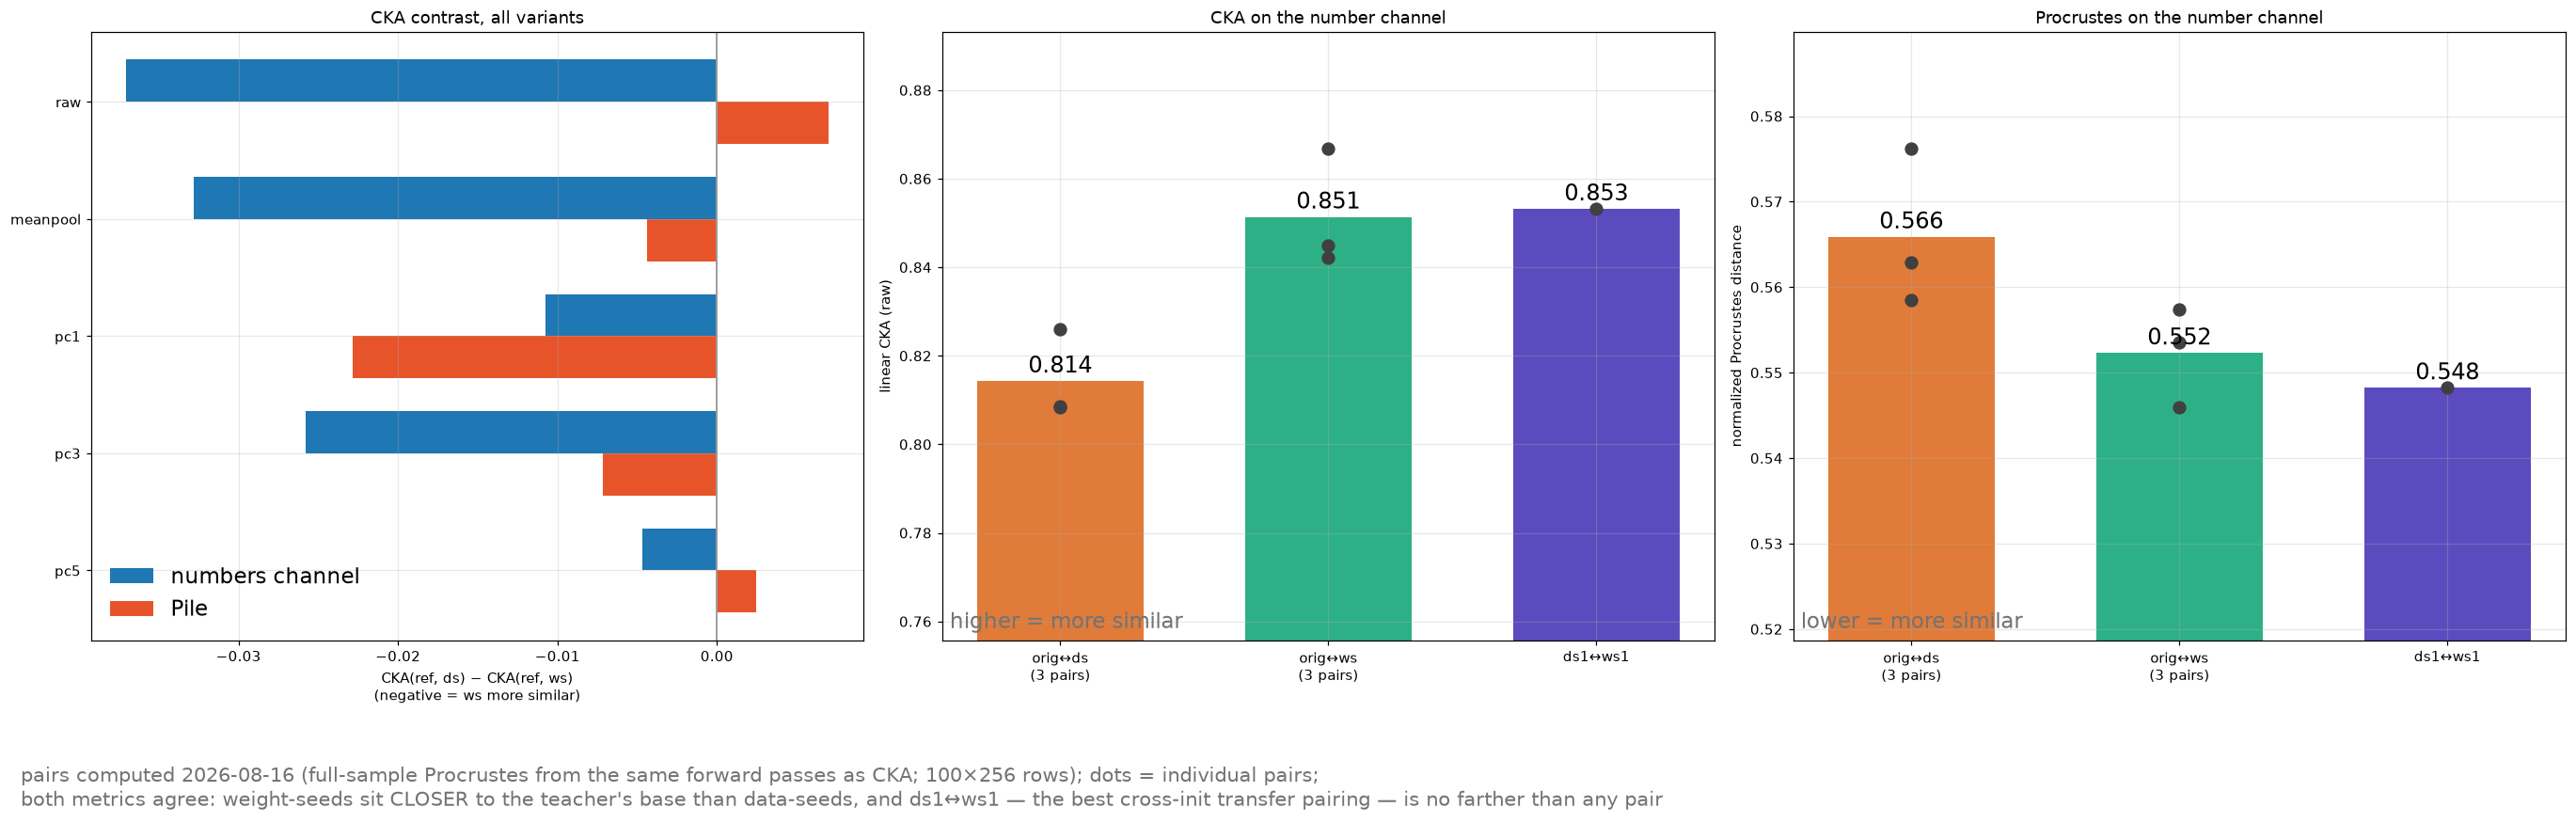

                   mean CKA (raw)  mean normalized Procrustes
orig↔ds (3 pairs)           0.814                       0.566
orig↔ws (3 pairs)           0.851                       0.552
ds1↔ws1                     0.853                       0.548


In [13]:
PAIRS_ROOT = OUTPUT_ROOT / "cka" / "pairs"
NUM_RUN = "numbers_base160m_prefix"
PROC_FIELD = 1  # column index of "normalized_distance" (fields order in summary.json)

# --- panel 1: d-vs-w contrast per variant, per run (from the loaded frame) ---
contrast = (df[df.group.isin(["primary_data", "primary_weight"])]
            .groupby(["run", "variant", "group"], observed=True)["diag_mean"].mean()
            .unstack("group"))
contrast["delta"] = contrast["primary_data"] - contrast["primary_weight"]

# --- panels 2-3: the three number-channel groups ---
# Pair runs are DISCOVERED, not hardcoded: any pairs dir prefixed with the numbers run tag.
pair_dirs = {p.name: p for p in sorted(PAIRS_ROOT.glob(f"{NUM_RUN}_*")) if p.is_dir()}
mtimes = []


def proc_mean(pair_dir, pair_label):
    """Mean over the 13 layer slots of the normalized Procrustes distance."""
    f = pair_dir / f"procrustes__{pair_label}__raw.npy"
    mtimes.append(f.stat().st_mtime)
    return float(np.nanmean(np.load(f)[:, PROC_FIELD]))


groups = [
    ("orig\u2194ds\n(3 pairs)", "primary_data", "#e07b39"),
    ("orig\u2194ws\n(3 pairs)", "primary_weight", "#2eb086"),
    ("ds1\u2194ws1", None, "#5b4bbf"),
]
cka_pts, proc_pts = {}, {}
for label, grp, _ in groups:
    if grp is None:  # the cross-arm pair: its own pair run, not in the base matrix run
        pd_dir = pair_dirs[f"{NUM_RUN}_ds1_ws1"]
        s = frames.read_json(pd_dir / "summary.json")
        cka_pts[label] = [r["diag_mean"] for r in s["rows"]
                          if r["variant"] == "raw" and r["group"] == "primary"]
        proc_pts[label] = [proc_mean(pd_dir, "data-seed1__weight-seed1")]
        continue
    d = df[(df.run == NUM_RUN) & (df.variant == "raw") & (df.group == grp)]
    cka_pts[label] = d["diag_mean"].tolist()
    proc_pts[label] = []
    for pair in d["pair"]:
        arm = pair.split("__")[1]                      # e.g. data-seed2
        tag = f"{NUM_RUN}_orig_{'ds' if arm.startswith('data') else 'ws'}{arm[-1]}"
        proc_pts[label].append(proc_mean(pair_dirs[tag], pair))

labels = [g[0] for g in groups]
colors = [g[2] for g in groups]
computed = pd.Timestamp(max(mtimes), unit="s").date()

fig, axes = plt.subplots(1, 3, figsize=(25, 8))

ax = axes[0]
h = 0.36
# deck panel order: raw, meanpool, then the PC-ablated variants
panel_variants = [v for v in ["raw", "meanpool", "pc1", "pc3", "pc5"] if v in variants]
ys = np.arange(len(panel_variants))
for off, (tag, color, name) in enumerate([(NUM_RUN, "#1f77b4", "numbers channel"),
                                          ("pile", "#e8542a", "Pile")]):
    vals = [contrast.loc[(tag, v), "delta"] for v in panel_variants]
    ax.barh(ys - (0.5 - off) * h, vals, height=h, color=color, label=name)
ax.axvline(0, color="0.6", linewidth=1.2)
ax.set_yticks(ys, panel_variants)
ax.invert_yaxis()
ax.set_xlabel("CKA(ref, ds) \u2212 CKA(ref, ws)\n(negative = ws more similar)")
ax.set_title("CKA contrast, all variants")
ax.legend(fontsize=15, loc="lower left", frameon=False)

for ax, pts, ylab, note, lo_pad in [
    (axes[1], cka_pts, "linear CKA (raw)", "higher = more similar", True),
    (axes[2], proc_pts, "normalized Procrustes distance", "lower = more similar", True),
]:
    means = [np.mean(pts[l]) for l in labels]
    ax.bar(labels, means, color=colors, width=0.62)
    for i, l in enumerate(labels):
        ax.scatter([i] * len(pts[l]), pts[l], s=70, color="0.25", zorder=3)
        ax.annotate(f"{means[i]:.3f}", (i, means[i]), xytext=(0, 6),
                    textcoords="offset points", ha="center", fontsize=16)
    allv = [v for l in labels for v in pts[l]] + means
    span = max(allv) - min(allv)
    ax.set_ylim(min(allv) - 0.9 * span, max(allv) + 0.45 * span)
    ax.set_ylabel(ylab)
    ax.text(0.01, 0.02, note, transform=ax.transAxes, fontsize=15, color="0.45")
axes[1].set_title("CKA on the number channel")
axes[2].set_title("Procrustes on the number channel")

agree = (np.mean(cka_pts[labels[0]]) < np.mean(cka_pts[labels[1]])
         and np.mean(proc_pts[labels[0]]) > np.mean(proc_pts[labels[1]])
         and np.mean(proc_pts[labels[2]]) <= max(np.mean(proc_pts[l]) for l in labels))
foot2 = ("both metrics agree: weight-seeds sit CLOSER to the teacher's base than "
         "data-seeds, and ds1\u2194ws1 \u2014 the best cross-init transfer pairing "
         "\u2014 is no farther than any pair") if agree else (
    "metrics DISAGREE \u2014 see the printed group means below")
fig.tight_layout()
fig.subplots_adjust(bottom=0.22)
fig.text(0.01, 0.02,
         f"pairs computed {computed} (full-sample Procrustes from the same forward "
         f"passes as CKA; 100\u00d7256 rows); dots = individual pairs;\n{foot2}",
         fontsize=14, color="0.45")
plt.show()

print(pd.DataFrame({"mean CKA (raw)": [np.mean(cka_pts[l]) for l in labels],
                    "mean normalized Procrustes": [np.mean(proc_pts[l]) for l in labels]},
                   index=[l.replace("\n", " ") for l in labels]).round(3))